# Part 5:  Vibe-Coding Emerging Optimizers on CIFAR Classification 

As large language models (LLMs) reshape software engineering, we are entering a new era of AI-assisted programming where human creativity and machine execution merge. Instead of focusing on every low-level implementation detail, developers can prioritize **ideas, exploration, and iteration speed**, while the model handles much of the routine coding. This is the essence of [**vibe coding**](https://en.wikipedia.org/wiki/Vibe_coding?utm_source=chatgpt.com): coding by “vibes” and letting AI accelerate the path from concept to working system. In this homework, you will practice vibe coding by using AI assistants such as [ChatGPT](https://chat.openai.com), [Gemini](https://gemini.google.com/app), or [Claude](https://www.anthropic.com/claude-code) to help design and implement optimizers for CIFAR image classification.  

---

## 1. What is *Vibe Coding*? 

**Vibe coding** is a paradigm popularized by Andrej Karpathy in 2025. It emphasizes generating most of the code through LLMs while the human programmer acts as a **guide, tester, and refiner**. Instead of carefully reviewing every line, you iterate based on execution results, keeping the creative process at the center.  

Karpathy put it simply:  
> *“Fully giving in to the vibes, embracing exponentials, and forgetting that the code even exists.”*  

**Learn more :**
- [IBM: What is Vibe Coding?](https://www.ibm.com/think/topics/vibe-coding?utm_source=chatgpt.com)  
- [Replit Blog: What is Vibe Coding?](https://blog.replit.com/what-is-vibe-coding?utm_source=chatgpt.com)  

---

## 2. Objectives 

- Understand and implement **novel optimizers** (Muon, Scion, SODA).  
- Practice **vibe coding** as a workflow with LLMs.  
- Compare optimizer performance on **CIFAR-10** across Transformer and ResNet architectures.  
- Analyze results critically and reflect on the coding process.  

---

## 3. Task Overview 

You will implement and compare four optimizers on **CIFAR-10 classification** with two architectures: a **Transformer**  and a **ResNet** .  

- **Optimizers**: Muon , Scion , SODA , Adam (baseline)  
- **Models**: Transformer, ResNet  
- **Comparison metrics**: convergence speed, final test accuracy , training stability  

---

## 4. Optimizers to Implement 

### (1) Muon 
Muon applies **Newton–Schulz orthonormalization** to gradient updates of 2D weight matrices, making them invariant to input conditioning.  
References:  
- [Muon Blog (Keller Jordan)](https://kellerjordan.github.io/posts/muon/?utm_source=chatgpt.com)  
- [Deriving Muon (Jeremy Bernstein)](https://jeremybernste.in/writing/deriving-muon?utm_source=chatgpt.com)  
- [Muon GitHub Repo](https://github.com/KellerJordan/Muon?utm_source=chatgpt.com)  
- [Convergence Bound (arXiv)](https://arxiv.org/abs/2507.01598?utm_source=chatgpt.com)  

---

### (2) Scion 
Scion constrains updates differently for hidden vs input/output layers, using **spectral norm** for hidden layers and **ℓ∞ norm** for others. This improves stability and hyperparameter transfer.  
References:  
- [Scion Paper](https://arxiv.org/abs/2502.07529)  
- [Scion Official Code](https://github.com/LIONS-EPFL/scion)  

---

### (3) SODA 
SODA wraps a base optimizer with a theoretically grounded, initialization-centered **1/k weight-decay schedule**, motivating us to test whether it improves CIFAR-10 training without tuning weight decay.  
References:  
- [SODA Paper (arXiv)](https://arxiv.org/pdf/2605.11172)  
- [SODA GitHub Repo](https://github.com/tmpethick/soda_code)  

---

### (4) Adam 
Adam is the standard baseline optimizer combining momentum and adaptive learning rates. Use either `Adam` or `AdamW` from PyTorch.

---

## 5. Steps & Deliverables 

1. **Model Implementation (5 pts)**  
   - Build a Transformer for CIFAR classification.  
   - Build a ResNet (ResNet-18 or similar).  

2. **Optimizer Integration (8 pts)**  
   - Implement Muon, Scion, SODA optimizers using your AI assistant in a form which is compatible with `torch.optim.Optimizer`.  
   - Use Adam as baseline.  

3. **Training & Evaluation (7 pts)**  
   - Train both models with all optimizers.  
   - Collect metrics: training loss, validation accuracy, time-to-accuracy.  
   - Present results with plots and a summary table.  

4. **Discussion & Reflection (5 pts)**  
   - Compare optimizers in terms of convergence speed, stability, and accuracy.  
   - Reflect on your experience using **vibe coding** with AI assistants.  
   - What worked well? What challenges did you face?  

---

Good luck and enjoy vibe-coding your way through optimizers!!


## Setup

In [51]:
# Install dependencies if needed:
%pip install torch torchvision matplotlib numpy pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 9.1 MB/s  0:00:01eta 0:00:01

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [40]:
# Load the necessary libraries
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
import numpy as np
import matplotlib.pyplot as plt


## Model implementation

In [41]:
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Standard CIFAR-10 data augmentation and normalization
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

batch_size = 128

# Prepare the datasets
train_dataset = torchvision.datasets.CIFAR10(
    root='./lib/data', train=True, download=True, transform=transform_train
)
test_dataset = torchvision.datasets.CIFAR10(
    root='./lib/data', train=False, download=True, transform=transform_test
)

# Prepare the data loaders
train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=2
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False, num_workers=2
)


In [ ]:
import torch

class CIFARTransformer(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # 1. Patch embedding layer
        self.patch_embed = nn.Conv2d(in_channels=3, out_channels=128, kernel_size=4, stride=4)
        
        # 2. Positional encoding and class token
        self.cls_token = nn.Parameter(torch.zeros(1, 1, 128))
        self.pos_embed = nn.Parameter(torch.zeros(1, 65, 128)) 
        
        # 3. Transformer Encoder layers
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=8, dim_feedforward=256, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=4)
        
        # 4. Classification head
        self.head = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.patch_embed(x) 
        x = x.flatten(2).transpose(1, 2) 
        
        B = x.shape[0]
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + self.pos_embed
        
        x = self.transformer(x)
        
        cls_out = x[:, 0]
        return self.head(cls_out)

In [ ]:
import torchvision.models as models

class CIFARResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # Load a base ResNet-18 model (untrained)
        self.resnet = models.resnet18(weights=None)
        
        # Adapt for CIFAR-10
        self.resnet.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.resnet.maxpool = nn.Identity()
        self.resnet.fc = nn.Linear(self.resnet.fc.in_features, num_classes)

    def forward(self, x):
        return self.resnet(x)

## Optimizer integration

In [44]:
import torch.optim as optim

def newton_schulz(G, steps=5):
    """Applies Newton-Schulz iteration to orthonormalize a matrix."""
    X = G.clone()
    X /= (X.norm() + 1e-8)
    for _ in range(steps):
        A = X @ X.T
        B = A @ X
        X = 1.5 * X - 0.5 * B
    return X

class Muon(optim.Optimizer):
    def __init__(self, params, lr=0.02, momentum=0.9, ns_steps=5):
        defaults = dict(lr=lr, momentum=momentum, ns_steps=ns_steps)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                state = self.state[p]
                
                # State initialization
                if len(state) == 0:
                    state['momentum_buffer'] = torch.zeros_like(p)
                
                buf = state['momentum_buffer']
                buf.mul_(group['momentum']).add_(grad)
                
                # Apply Newton-Schulz for 2D parameters (matrices)
                if len(p.shape) == 2:
                    update = newton_schulz(buf, steps=group['ns_steps'])
                else:
                    # Fallback to standard momentum for 1D biases/norms
                    update = buf
                
                p.add_(update, alpha=-group['lr'])
        return loss


In [45]:
class Scion(optim.Optimizer):
    def __init__(self, params, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        defaults = dict(lr=lr, beta1=beta1, beta2=beta2, eps=eps)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                state = self.state[p]

                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)

                exp_avg, exp_avg_sq = state['exp_avg'], state['exp_avg_sq']
                state['step'] += 1

                exp_avg.mul_(group['beta1']).add_(grad, alpha=1 - group['beta1'])
                exp_avg_sq.mul_(group['beta2']).addcmul_(grad, grad, value=1 - group['beta2'])

                denom = exp_avg_sq.sqrt().add_(group['eps'])
                update = exp_avg / denom

                # Scion constraint: normalize update by spectral norm (2D) or L_inf (1D)
                if len(p.shape) == 2:
                    # Approximation of spectral norm using Frobenius norm for speed
                    norm = update.norm(p=2) + group['eps']
                else:
                    norm = update.abs().max() + group['eps']
                
                update.div_(norm)
                p.add_(update, alpha=-group['lr'])
        return loss

In [46]:
class SODA(optim.Optimizer):
    def __init__(self, base_optimizer_class, params, lr=0.001, wd_init=0.1, **kwargs):
        self.base_opt = base_optimizer_class(params, lr=lr, **kwargs)
        self.wd_init = wd_init
        self.k = 1 # Step counter for 1/k schedule
        # Store param_groups to comply with Optimizer protocol
        self.param_groups = self.base_opt.param_groups 
        self.state = self.base_opt.state
        defaults = dict(lr=lr, wd_init=wd_init)
        super().__init__(self.param_groups, defaults)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        # Apply 1/k weight decay manually before optimizer step
        current_wd = self.wd_init / self.k
        for group in self.base_opt.param_groups:
            for p in group['params']:
                if p.grad is not None:
                    p.mul_(1.0 - group['lr'] * current_wd)
        
        self.base_opt.step()
        self.k += 1
        return loss
    
    def zero_grad(self):
        self.base_opt.zero_grad()

In [47]:
# Helper function to initialize optimizers dynamically during training
def get_optimizer(opt_name, model_params):
    if opt_name == 'Adam':
        return optim.Adam(model_params, lr=0.001)
    elif opt_name == 'Muon':
        return Muon(model_params, lr=0.02)
    elif opt_name == 'Scion':
        return Scion(model_params, lr=0.001)
    elif opt_name == 'SODA':
        return SODA(optim.Adam, model_params, lr=0.001, wd_init=0.1)
    else:
        raise ValueError("Unknown optimizer")

## Training and evaluation

In [48]:
import time

def train_and_evaluate(model, optimizer, train_loader, test_loader, epochs=5, device='cuda'):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    
    history = {'train_loss': [], 'test_acc': [], 'time_elapsed': []}
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            
        avg_train_loss = running_loss / len(train_loader)
        history['train_loss'].append(avg_train_loss)
        
        # Evaluation
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, targets in test_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()
                
        test_acc = 100. * correct / total
        history['test_acc'].append(test_acc)
        history['time_elapsed'].append(time.time() - start_time)
        
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_train_loss:.3f} | Acc: {test_acc:.2f}%")
        
    return history

In [49]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

models_to_test = {
    'Transformer': CIFARTransformer,
    'ResNet': CIFARResNet
}
optimizers_to_test = ['Adam', 'Muon', 'Scion', 'SODA']

results = {}

# Run a short training loop (e.g., 5 epochs) for demonstration. Increase for final results.
EPOCHS = 5

for model_name, ModelClass in models_to_test.items():
    results[model_name] = {}
    for opt_name in optimizers_to_test:
        print(f"\n--- Training {model_name} with {opt_name} ---")
        
        # Instantiate fresh model and optimizer
        model = ModelClass()
        optimizer = get_optimizer(opt_name, model.parameters())
        
        # Train and save history
        history = train_and_evaluate(model, optimizer, train_loader, test_loader, epochs=EPOCHS, device=device)
        results[model_name][opt_name] = history

Using device: cpu

--- Training Transformer with Adam ---
Epoch 1/5 | Loss: 1.768 | Acc: 45.11%
Epoch 2/5 | Loss: 1.397 | Acc: 53.24%
Epoch 3/5 | Loss: 1.255 | Acc: 56.79%
Epoch 4/5 | Loss: 1.162 | Acc: 62.01%
Epoch 5/5 | Loss: 1.101 | Acc: 62.10%

--- Training Transformer with Muon ---
Epoch 1/5 | Loss: 1.818 | Acc: 40.67%
Epoch 2/5 | Loss: 1.528 | Acc: 44.77%
Epoch 3/5 | Loss: 1.415 | Acc: 51.41%
Epoch 4/5 | Loss: 1.353 | Acc: 54.79%
Epoch 5/5 | Loss: 1.300 | Acc: 54.20%

--- Training Transformer with Scion ---
Epoch 1/5 | Loss: 1.965 | Acc: 33.15%
Epoch 2/5 | Loss: 1.777 | Acc: 37.53%
Epoch 3/5 | Loss: 1.666 | Acc: 42.73%
Epoch 4/5 | Loss: 1.582 | Acc: 45.02%
Epoch 5/5 | Loss: 1.521 | Acc: 47.84%

--- Training Transformer with SODA ---
Epoch 1/5 | Loss: 1.769 | Acc: 44.26%
Epoch 2/5 | Loss: 1.396 | Acc: 54.83%
Epoch 3/5 | Loss: 1.244 | Acc: 57.61%
Epoch 4/5 | Loss: 1.148 | Acc: 60.77%
Epoch 5/5 | Loss: 1.080 | Acc: 63.23%

--- Training ResNet with Adam ---
Epoch 1/5 | Loss: 1.359 | 

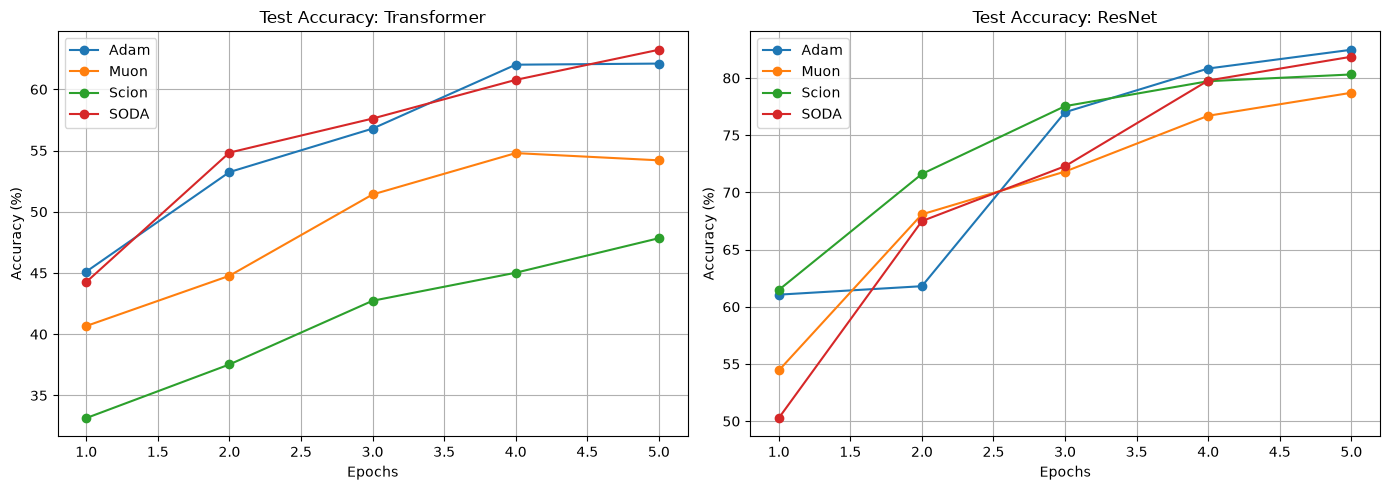

,Model,Optimizer,Final Accuracy (%),Total Time (s)
0,Transformer,Adam,62.10,590.47
1,Transformer,Muon,54.20,629.20
2,Transformer,Scion,47.84,589.30
3,Transformer,SODA,63.23,606.60
4,ResNet,Adam,82.47,4144.04
5,ResNet,Muon,78.71,5202.38
6,ResNet,Scion,80.31,4052.80
7,ResNet,SODA,81.86,3794.77


In [52]:
import pandas as pd

# Plotting Test Accuracy over Epochs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, model_name in enumerate(models_to_test.keys()):
    ax = axes[i]
    for opt_name in optimizers_to_test:
        acc_history = results[model_name][opt_name]['test_acc']
        ax.plot(range(1, EPOCHS + 1), acc_history, label=opt_name, marker='o')
        
    ax.set_title(f"Test Accuracy: {model_name}")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Accuracy (%)")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

# Generating Summary Table
summary_data = []
for model_name in models_to_test.keys():
    for opt_name in optimizers_to_test:
        final_acc = results[model_name][opt_name]['test_acc'][-1]
        total_time = results[model_name][opt_name]['time_elapsed'][-1]
        summary_data.append({
            'Model': model_name,
            'Optimizer': opt_name,
            'Final Accuracy (%)': round(final_acc, 2),
            'Total Time (s)': round(total_time, 2)
        })

summary_df = pd.DataFrame(summary_data)
display(summary_df)

## Discussion

*Write your answer here.*


## Reflection on AI-assisted coding

*Write your answer here.*
